<a href="https://colab.research.google.com/github/HoangMinhne0903/6451071046_Lab1_Phan_1/blob/main/6451071046_LAB1_Phan1_BaiTapThem_Trang30.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phần 1 - Bài tập thêm (Trang 30): Dữ liệu môi trường nhà xưởng (tb_tracking.xlsx)



In [ ]:
print("Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046")

# Cài đặt thư viện nếu cần:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# a) Đọc file và thêm tiêu đề các cột
df = pd.read_excel("tb_tracking.xlsx", header=None)
df.columns = ["id", "device_id", "co_level", "humidity", "temperature", "time"]

print("Dữ liệu gốc (5 dòng đầu):")
print(df.head())
print("\nKích thước:", df.shape)
print("\nKiểu dữ liệu:")
print(df.dtypes)


Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046
Dữ liệu gốc (5 dòng đầu):
    id  device_id  co_level  humidity  temperature                time
0  1.0        1.0       2.0       3.0          4.0 2016-12-20 12:52:29
1  2.0        1.0       2.0       3.0          4.0 2016-12-20 12:52:31
2  3.0      100.0       2.0       3.0          4.0 2016-12-20 12:52:35
3  4.0      100.0       2.0       3.0        400.0 2016-12-20 12:52:37
4  5.0        1.0       2.0       3.0          4.0 2016-12-20 13:02:01

Kích thước: (33340, 6)

Kiểu dữ liệu:
id                    float64
device_id             float64
co_level              float64
humidity              float64
temperature           float64
time           datetime64[ns]
dtype: object


In [ ]:
print("Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046")

# b) Lọc bỏ dữ liệu trước ngày 03/01/2018 (không chính xác)
df["time"] = pd.to_datetime(df["time"])

cutoff = pd.Timestamp("2018-01-03")
df_clean = df[df["time"] >= cutoff].copy()

print(f"Dữ liệu gốc: {len(df)} dòng")
print(f"Sau khi loại dữ liệu trước 03/01/2018: {len(df_clean)} dòng")
print(f"Số dòng bị xóa: {len(df) - len(df_clean)} dòng")
print("\nDữ liệu sau lọc:")
print(df_clean.head())


Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046
Dữ liệu gốc: 33340 dòng
Sau khi loại dữ liệu trước 03/01/2018: 1918 dòng
Số dòng bị xóa: 31422 dòng

Dữ liệu sau lọc:
            id  device_id  co_level  humidity  temperature                time
31419  31420.0        1.0       2.0       3.0          4.0 2018-01-03 13:11:07
31420  31421.0        1.0       2.0       3.0          4.0 2018-01-03 13:15:10
31421  31422.0    99005.0      58.0      26.0          0.0 2018-01-03 13:17:30
31422  31423.0    99005.0      58.0      26.0          0.0 2018-01-03 13:19:21
31423  31424.0    99005.0      58.0      26.0          0.0 2018-01-03 13:24:17


In [ ]:
print("Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046")

# c) Trích xuất thời điểm đo trong ngày tính theo phút
df_clean["minutes"] = df_clean["time"].dt.hour * 60 + df_clean["time"].dt.minute

print("5 dòng đầu với cột minutes:")
print(df_clean[["time", "minutes", "co_level", "humidity", "temperature"]].head())
print("\nThống kê cột minutes:")
print(df_clean["minutes"].describe())


Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046
5 dòng đầu với cột minutes:
                     time  minutes  co_level  humidity  temperature
31419 2018-01-03 13:11:07      791       2.0       3.0          4.0
31420 2018-01-03 13:15:10      795       2.0       3.0          4.0
31421 2018-01-03 13:17:30      797      58.0      26.0          0.0
31422 2018-01-03 13:19:21      799      58.0      26.0          0.0
31423 2018-01-03 13:24:17      804      58.0      26.0          0.0

Thống kê cột minutes:
count    1918.000000
mean      709.421272
std       391.869731
min         1.000000
25%       396.000000
50%       713.000000
75%       992.250000
max      1439.000000
Name: minutes, dtype: float64


Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046


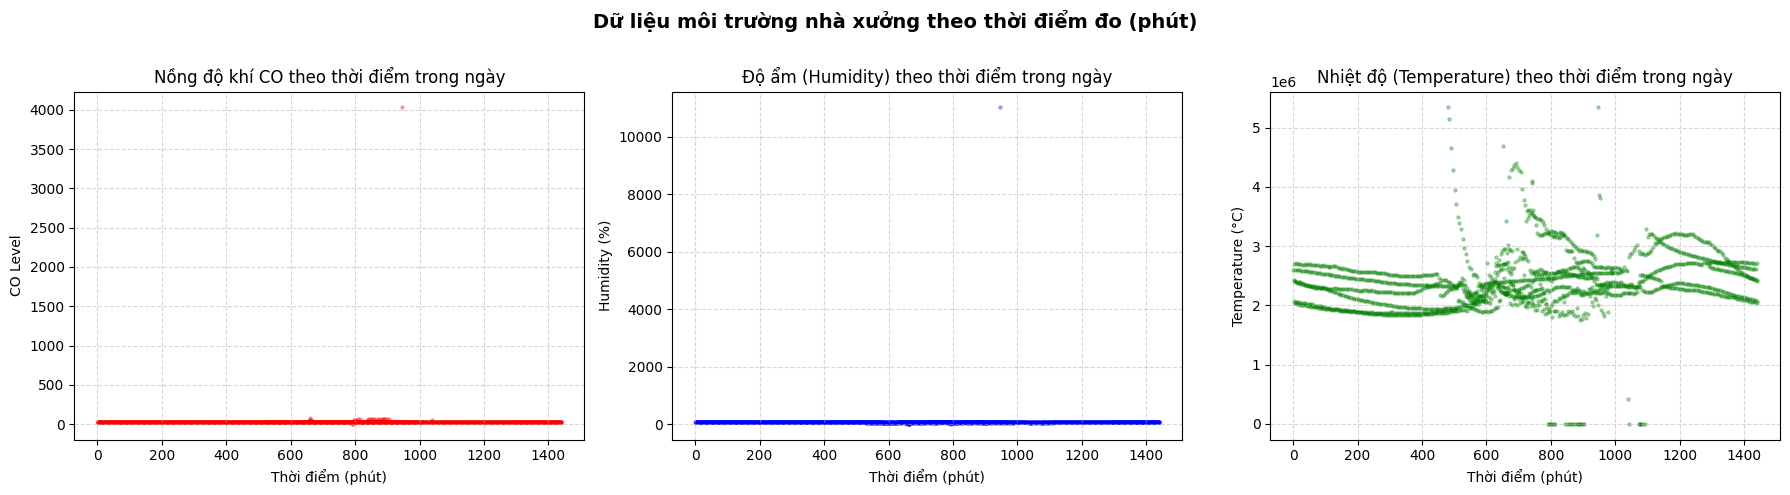

In [ ]:
print("Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046")

# d) Vẽ scatter plots: CO, humidity, temperature theo minutes
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(df_clean["minutes"], df_clean["co_level"], alpha=0.3, color="red", s=5)
axes[0].set_title("Nồng độ khí CO theo thời điểm trong ngày")
axes[0].set_xlabel("Thời điểm (phút)")
axes[0].set_ylabel("CO Level")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].scatter(df_clean["minutes"], df_clean["humidity"], alpha=0.3, color="blue", s=5)
axes[1].set_title("Độ ẩm (Humidity) theo thời điểm trong ngày")
axes[1].set_xlabel("Thời điểm (phút)")
axes[1].set_ylabel("Humidity (%)")
axes[1].grid(True, linestyle="--", alpha=0.5)

axes[2].scatter(df_clean["minutes"], df_clean["temperature"], alpha=0.3, color="green", s=5)
axes[2].set_title("Nhiệt độ (Temperature) theo thời điểm trong ngày")
axes[2].set_xlabel("Thời điểm (phút)")
axes[2].set_ylabel("Temperature (°C)")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Dữ liệu môi trường nhà xưởng theo thời điểm đo (phút)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
